# Task 52: Runtime, Memory, and Performance Benchmark

Measure fit and inference time, approximate Python-traced peak memory, and held-out quality for several scratch models. Interpret the results as local, hardware-dependent measurements.

,Fit seconds,Inference seconds,Peak traced extra MB,accuracy,precision,recall,f1
Model,,,,,,,
k-NN (k=7),0.0000,0.0063,0.0001,0.8361,0.8286,0.8788,0.8529
Decision stump,0.1345,0.0001,0.0080,0.6885,0.7333,0.6667,0.6984
Logistic regression,0.3429,0.0002,0.0201,0.7869,0.7632,0.8788,0.8169
Random stump forest,0.6989,0.0002,0.0397,0.6885,0.7333,0.6667,0.6984


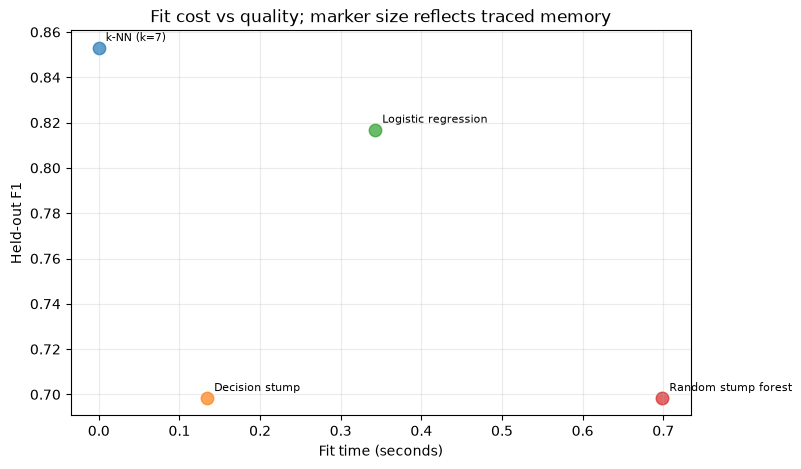

Decision guidance: a simple model may be preferable when latency, memory, and explanation matter; forests spend more fit time to reduce variance; k-NN has cheap fitting but expensive inference. Validate timing on deployment hardware.
tracemalloc reports Python-traced peak allocations, not complete process or native-library memory.


In [1]:
from pathlib import Path
import gc
import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_52_Model_Runtime_Memory_Benchmark/heart.csv'),Path('Heart_Disease_Tasks/Task_52_Model_Runtime_Memory_Benchmark/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train,test=split(y,.8,52);Xtr,Xte=X[train],X[test];ytr,yte=y[train],y[test]
mean,std=Xtr.mean(0),Xtr.std(0);std[std==0]=1;Xtr,Xte=(Xtr-mean)/std,(Xte-mean)/std

class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1000):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def predict(self,x):return (1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))>=.5).astype(int)
class Stump:
    def fit(self,x,y):
        best=None
        for j in range(x.shape[1]):
            v=np.unique(x[:,j])
            for t in (v[:-1]+v[1:])/2:
                m=x[:,j]<=t
                if not m.any() or m.all():continue
                lp=float(y[m].mean());rp=float(y[~m].mean());loss=m.mean()*lp*(1-lp)+(~m).mean()*rp*(1-rp)
                if best is None or loss<best[0]:best=(loss,j,t,lp,rp)
        if best is None:self.j,self.t,self.lp,self.rp=0,0,float(y.mean()),float(y.mean())
        else:_,self.j,self.t,self.lp,self.rp=best
        return self
    def predict(self,x):return (np.where(x[:,self.j]<=self.t,self.lp,self.rp)>=.5).astype(int)
class RandomStumpForest:
    def fit(self,x,y,trees=8,seed=52):
        rng=np.random.default_rng(seed);self.models=[]
        for _ in range(trees):
            ids=rng.integers(0,len(y),len(y));self.models.append(Stump().fit(x[ids],y[ids]))
        return self
    def predict(self,x):return (np.mean([m.predict(x) for m in self.models],axis=0)>=.5).astype(int)
class KNN:
    def __init__(self,k=7):self.k=k
    def fit(self,x,y):self.x,self.y=x,y;return self
    def predict(self,x):
        result=[]
        for row in x:
            ids=np.argsort(np.sum((self.x-row)**2,axis=1),kind='stable')[:self.k];result.append(int(self.y[ids].mean()>=.5))
        return np.array(result)

def measure(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    precision=tp/(tp+fp) if tp+fp else 0.;recall=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.}

factories={'Logistic regression':lambda:Logistic(),'Decision stump':lambda:Stump(),'Random stump forest':lambda:RandomStumpForest(),'k-NN (k=7)':lambda:KNN(7)}
rows=[]
for name,factory in factories.items():
    gc.collect();model=factory();tracemalloc.start();before,_=tracemalloc.get_traced_memory();tracemalloc.reset_peak();start=time.perf_counter()
    if name=='Random stump forest':model.fit(Xtr,ytr,trees=8)
    else:model.fit(Xtr,ytr)
    fit_seconds=time.perf_counter()-start;_,peak=tracemalloc.get_traced_memory();peak_mb=max(0,peak-before)/1024**2;tracemalloc.stop()
    start=time.perf_counter();pred=model.predict(Xte);predict_seconds=time.perf_counter()-start
    rows.append({'Model':name,'Fit seconds':fit_seconds,'Inference seconds':predict_seconds,'Peak traced extra MB':peak_mb,**measure(yte,pred)})
results=pd.DataFrame(rows).set_index('Model').sort_values('Fit seconds')
display(results.round(4))
fig,ax=plt.subplots(figsize=(8,5))
for name,row in results.iterrows():
    ax.scatter(row['Fit seconds'],row['f1'],s=80+row['Peak traced extra MB']*40,alpha=.7);ax.annotate(name,(row['Fit seconds'],row['f1']),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.set_xlabel('Fit time (seconds)');ax.set_ylabel('Held-out F1');ax.set_title('Fit cost vs quality; marker size reflects traced memory');ax.grid(alpha=.25);plt.show()
print('Decision guidance: a simple model may be preferable when latency, memory, and explanation matter; forests spend more fit time to reduce variance; k-NN has cheap fitting but expensive inference. Validate timing on deployment hardware.')
print('tracemalloc reports Python-traced peak allocations, not complete process or native-library memory.')